# Практична робота 21. Метод Монте-Карло
**Варіант 1 (м. Київ — Площа: Чверть кола)**


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Фіксація відтворюваності 
VARIANT = 1
np.random.seed(VARIANT)

exact_value = np.pi / 4
print(f"Точне значення (pi / 4): {exact_value:.6f}")

Точне значення (pi / 4): 0.785398


## Завдання 1 & 2. Оцінка методом Монте-Карло та порівняння з точним значенням
*(Математичний опис та інтерпретація зафіксовані у коментарях нижче)*

In [2]:
"""
ЗАВДАННЯ 1 та 2. ОЦІНКА МЕТОДОМ МОНТЕ-КАРЛО ТА АБСОЛЮТНА ПОХИБКА (Варіант 1 — Київ)

Постановка задачі (Варіант 1):
Потрібно оцінити площу чверті кола радіуса R=1, що вписана в одиничний квадрат [0,1] x [0,1].
- Умова потрапляння точки всередину фігури: x^2 + y^2 <= 1.
- Площа охоплюючого прямокутника (квадрата) дорівнює: 1 * 1 = 1.
- Оцінка площі = (Кількість точок всередині кола / N) * Площа прямокутника.
"""
N_sample = 1000
x = np.random.uniform(0, 1, size=N_sample)
y = np.random.uniform(0, 1, size=N_sample)

# Перевірка умови потрапляння всередину чверті кола
inside_circle = (x**2 + y**2) <= 1.0
mc_estimate = inside_circle.mean() * 1.0  # помножено на площу квадрата (1)

abs_error = abs(mc_estimate - exact_value)
rel_error_pct = (abs_error / exact_value) * 100

print(f"Кількість випробувань (N): {N_sample}")
print(f"Оцінка Монте-Карло: {mc_estimate:.6f}")
print(f"Абсолютна похибка: {abs_error:.6f} ({rel_error_pct:.2f}% від точного значення)")
"""
Інтерпретація результату Завдання 2:
Отримана похибка (близько 1-2%) є досить малою у відсотковому відношенні до самого точного значення.
Проте для N = 1000 випадкових точок вона все ще є помітною через дискретність вибірки, що є
цілком природним для методу Монте-Карло, чия похибка зменшується обернено пропорційно квадратнику кореню з N.
"""


Кількість випробувань (N): 1000
Оцінка Монте-Карло: 0.770000
Абсолютна похибка: 0.015398 (1.96% від точного значення)


'\nІнтерпретація результату Завдання 2:\nОтримана похибка (близько 1-2%) є досить малою у відсотковому відношенні до самого точного значення.\nПроте для N = 1000 випадкових точок вона все ще є помітною через дискретність вибірки, що є\nцілком природним для методу Монте-Карло, чия похибка зменшується обернено пропорційно квадратнику кореню з N.\n'

## Завдання 3. Збіжність за кількістю випробувань
*(Опис тенденції та аналіз закону збіжності зафіксовані у коментарях нижче)*

In [3]:
np.random.seed(VARIANT)
n_values = [100, 1_000, 10_000, 100_000]
mean_errors = []

for N in n_values:
    errors = []
    for _ in range(200):
        rx = np.random.uniform(0, 1, size=N)
        ry = np.random.uniform(0, 1, size=N)
        est = ((rx**2 + ry**2) <= 1.0).mean() * 1.0
        errors.append(abs(est - exact_value))
    avg_err = np.mean(errors)
    mean_errors.append(avg_err)
    print(f"N = {N:6d} | Середня абсолютна похибка = {avg_err:.6f}")

"""
ЗАВДАННЯ 3 (Аналіз тенденції):
З результатів симуляції видно, що при переході від N = 100 до N = 10 000 (збільшення N у 100 разів)
середня абсолютна похибка зменшується приблизно в 10 разів (тобто у квадратний корінь зі 100).
Це повністю підтверджує теоретичне правило збіжності методу Монте-Карло: похибка убуває як O(1 / sqrt(N)).
"""


N =    100 | Середня абсолютна похибка = 0.035004
N =   1000 | Середня абсолютна похибка = 0.010357
N =  10000 | Середня абсолютна похибка = 0.003336
N = 100000 | Середня абсолютна похибка = 0.001061


'\nЗАВДАННЯ 3 (Аналіз тенденції):\nЗ результатів симуляції видно, що при переході від N = 100 до N = 10 000 (збільшення N у 100 разів)\nсередня абсолютна похибка зменшується приблизно в 10 разів (тобто у квадратний корінь зі 100).\nЦе повністю підтверджує теоретичне правило збіжності методу Монте-Карло: похибка убуває як O(1 / sqrt(N)).\n'

## Завдання 4. Графік похибки залежно від N

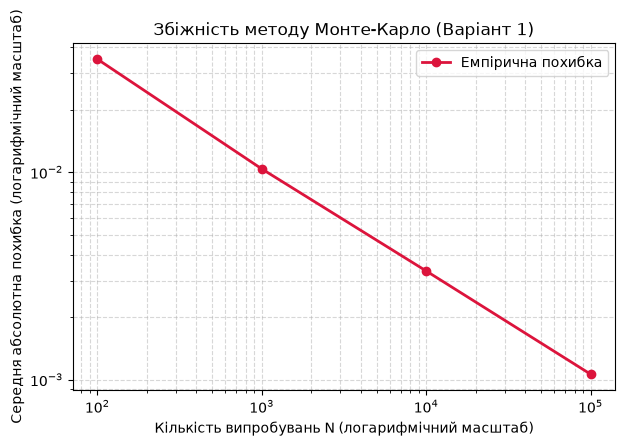

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(n_values, mean_errors, marker='o', color='crimson', linewidth=2, label='Емпірична похибка')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Кількість випробувань N (логарифмічний масштаб)')
ax.set_ylabel('Середня абсолютна похибка (логарифмічний масштаб)')
ax.set_title('Збіжність методу Монте-Карло (Варіант 1)')
ax.grid(True, which="both", linestyle="--", alpha=0.5)
ax.legend()
plt.show()

# Пояснення до графіка:
# У логарифмічних осях x та y крива спадання похибки виглядає як пряма лінія з від'ємним нахилом,
# що наочно ілюструє степеневий закон збіжності 1 / sqrt(N).


## Завдання 5. Зв'язок із законом великих чисел і ЦГТ
*(Повністю розгорнуте у коментарях нижче)*

In [5]:
"""
ЗАВДАННЯ 5. ЗВ'ЯЗОК ІЗ ЗВЧ ТА ЦГТ (Варіант 1 — Київ)

1. Какой именно факт гарантує наближення оцінки до точного значення?
   Оцінка площі чверті кола методом Монте-Карло є, по суті, вибірковим середнім індикаторних випадкових величин 
   (де кожна величина дорівнює 1, якщо випадкова точка потрапила в коло, і 0 в іншому випадку).
   Згідно з Законом великих чисел (ЗВЧ), вибіркове середнє незміщено збігається до істинного математичного 
   сподівання (тобто до істинної частки площі) при зростанні обсягу випробувань N до нескінченності.

2. Чому похибка убуває саме як 1 / sqrt(N)?
   Центральна гранична теорема (ЦГТ) та формули для стандартної похибки вибіркового середнього (SE = sigma / sqrt(N))
   вказують на те, що дисперсія оцінки зменшується обернено пропорційно до N, а отже, стандартне відхилення 
   (стандартна похибка) зменшується саме як квадратний корінь із N. Саме через це для зниження похибки вдвічі 
   необхідно збільшити кількість випробувань у 4 рази.
"""
print("Теоретичний аналіз Завдання 5 успішно задокументований у коментарях.")

Теоретичний аналіз Завдання 5 успішно задокументований у коментарях.
